In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output

In [3]:
dataset = pd.read_csv(r'C:\Users\86134\CISC7204\cisc7204-sugex08-MC566422\Practices02\world_cities_pop.csv',low_memory=False)

In [9]:
dataset = dataset.rename(columns={'Latitude': 'lat', 'Longitude': 'lon'})

df_europe = dataset[
    (dataset['lon'] >= -15) & (dataset['lon'] <= 45) & 
    (dataset['lat'] >= 35) & (dataset['lat'] <= 72)
].copy()


df_z = df_europe[df_europe['City'].astype(str).str.startswith('Z', na=False)]

print(f"📊 数据总量: {len(dataset)} | 🇪🇺 欧洲数据量: {len(df_europe)} | 🏙️ Z开头城市量: {len(df_z)}")
display(df_z.head())

📊 数据总量: 3173958 | 🇪🇺 欧洲数据量: 912230 | 🏙️ Z开头城市量: 0


,Country,City,AccentCity,Region,Population,lat,lon


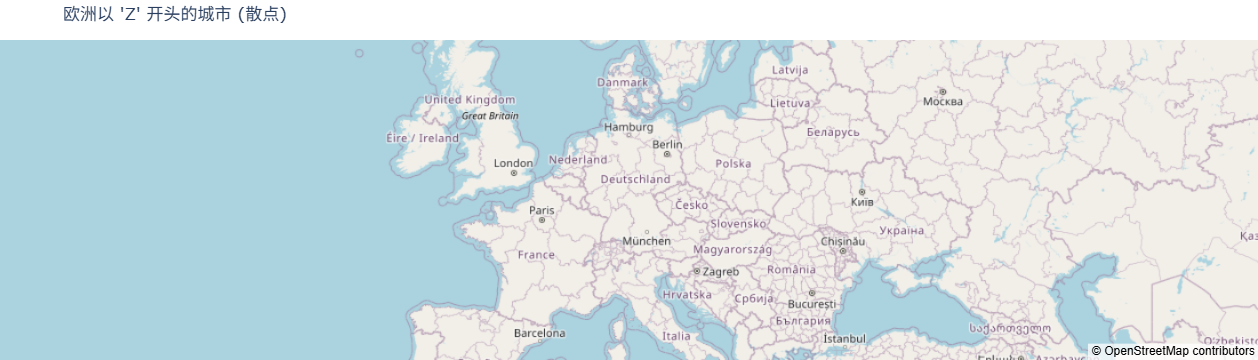

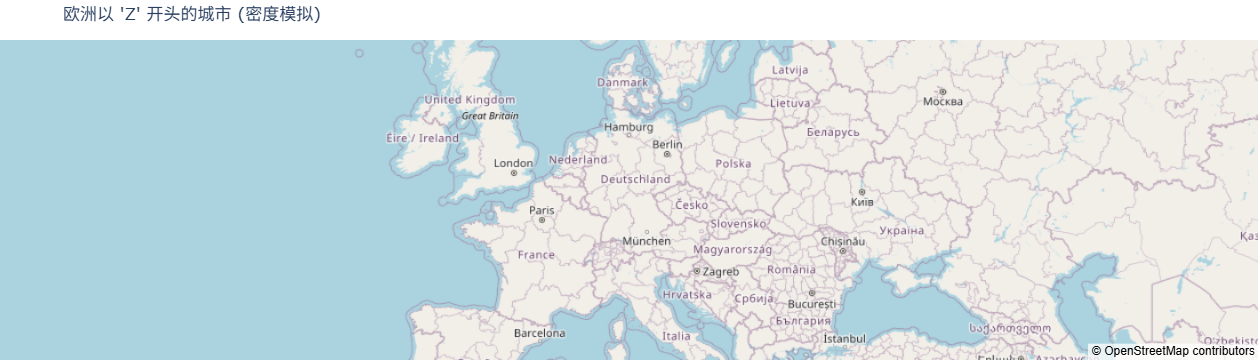

In [10]:
europe_center = dict(lat=50, lon=10)
fig_dots = px.scatter_map(
    df_z, lat="lat", lon="lon",
    hover_name="City",
    hover_data={"Country": True, "City": False},
    zoom=3, center=europe_center,
    title="欧洲以 'Z' 开头的城市 (散点)"
)
fig_dots.update_layout(map_style="open-street-map", margin={"r":0,"t":40,"l":0,"b":0})
fig_dots.show()

fig_voronoi = px.density_map(
    df_z, lat="lat", lon="lon",
    radius=10,
    color_continuous_scale='Reds', 
    opacity=0.6,
    zoom=3, center=europe_center,
    title="欧洲以 'Z' 开头的城市 (密度模拟)"
)
fig_voronoi.update_layout(map_style="open-street-map", margin={"r":0,"t":40,"l":0,"b":0})
fig_voronoi.show()

In [11]:
letters = [chr(i) for i in range(65, 91)]
out = widgets.Output()

def draw_layer(letter):
    df_current = df_europe[df_europe['City'].astype(str).str.startswith(letter, na=False)]
    
    with out:
        clear_output(wait=True)
        if df_current.empty:
            print(f"⚠️ 没有找到以 '{letter}' 开头的欧洲城市。")
            return
            
        fig = px.scatter_map(
            df_current, lat="lat", lon="lon",
            hover_name="City", 
            hover_data={"Country": True, "City": False},
            zoom=3, center=europe_center,
            title=f"🌍 欧洲以 '{letter}' 开头的城市"
        )
        fig.update_traces(marker=dict(size=8, color='red', opacity=0.8))
        fig.update_layout(map_style="open-street-map", margin={"r":0,"t":40,"l":0,"b":0}, height=600)
        fig.show()

slider = widgets.SelectionSlider(options=letters, value='A', description='当前字母:')
btn_prev = widgets.Button(description="← 上一步", button_style='info')
btn_next = widgets.Button(description="下一步 →", button_style='info')

def prev_click(b):
    idx = letters.index(slider.value)
    slider.value = letters[(idx - 1) % 26]

def next_click(b):
    idx = letters.index(slider.value)
    slider.value = letters[(idx + 1) % 26]

btn_prev.on_click(prev_click)
btn_next.on_click(next_click)
slider.observe(lambda change: draw_layer(change.new), names='value')

display(widgets.HBox([btn_prev, slider, btn_next]))
display(out)

draw_layer('A')

Output()